In [ ]:
# Гипотезы
# 1. Вернувшиеся посетители делают покупки чаще новых посетителей
# 2. У покупателей `PageValues` выше, а `BounceRates` и `ExitRates` ниже, чем у непокупателей
# 3. Accuracy у всех моделей будет 80-90%, а F1 по классу «купил» 10-30%, так как покупателей 15% от всех посетителей, а непокупателей 85%
# 4. Случайный лес даст F1 выше, чем Ridge, потому что зависимости
#    между признаками нелинейные
# 5. У дерева при `max_depth` больше 8-10 F1 на обучающей выборке будет возрастающей функциией, а на тестовой выборке убывающей
# 6. Ridge с `class_weight="balanced"` поднимет F1 минимум на 0.1,
#    потому что перестанет игнорировать редкий класс
# 7. `PageValues` окажется самым важным признаком у случайного леса, и без него F1 леса упадёт больше чем на 0.1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import RidgeClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

df = pd.read_csv(r"C:\Users\A\Documents\online_shoppers_intention.csv")
print(df.shape)
df.info()
print(df["Revenue"].value_counts(normalize=True))

X = df.drop(columns="Revenue")
y = df["Revenue"].astype(int)
X["Weekend"] = X["Weekend"].astype(int)

cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
num_cols = [c for c in X.columns if c not in cat_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

prep = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

(12330, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficTyp

0
                           count         mean          std  min         25%  \
Administrative           12330.0     2.315166     3.321784  0.0    0.000000   
Administrative_Duration  12330.0    80.818611   176.779107  0.0    0.000000   
Informational            12330.0     0.503569     1.270156  0.0    0.000000   
Informational_Duration   12330.0    34.472398   140.749294  0.0    0.000000   
ProductRelated           12330.0    31.731468    44.475503  0.0    7.000000   
ProductRelated_Duration  12330.0  1194.746220  1913.669288  0.0  184.137500   
BounceRates              12330.0     0.022191     0.048488  0.0    0.000000   
ExitRates                12330.0     0.043073     0.048597  0.0    0.014286   
PageValues               12330.0     5.889258    18.568437  0.0    0.000000   
SpecialDay               12330.0     0.061427     0.198917  0.0    0.000000   
OperatingSystems         12330.0     2.124006     0.911325  1.0    2.000000   
Browser                  12330.0     2.357097     

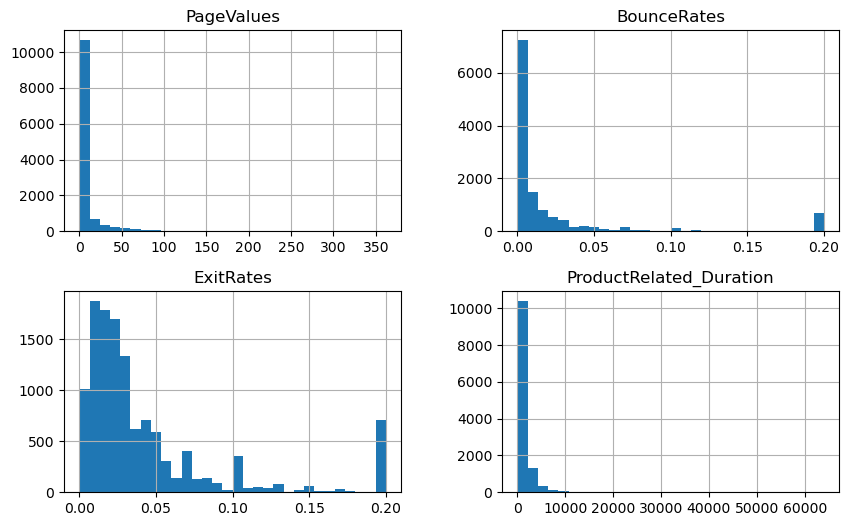

                         Administrative  Administrative_Duration  \
Administrative                     1.00                     0.60   
Administrative_Duration            0.60                     1.00   
Informational                      0.38                     0.30   
Informational_Duration             0.26                     0.24   
ProductRelated                     0.43                     0.29   
ProductRelated_Duration            0.37                     0.36   
BounceRates                       -0.22                    -0.14   
ExitRates                         -0.32                    -0.21   
PageValues                         0.10                     0.07   
SpecialDay                        -0.09                    -0.07   
OperatingSystems                  -0.01                    -0.01   
Browser                           -0.03                    -0.02   
Region                            -0.01                    -0.01   
TrafficType                       -0.03         

In [15]:
print(df.isna().sum().sum())
print(df.describe().T)

df[["PageValues", "BounceRates", "ExitRates", "ProductRelated_Duration"]].hist(bins=30, figsize=(10, 6))
plt.show()

print(df.corr(numeric_only=True).round(2))

In [17]:
# Гипотеза 1: вернувшиеся посетители делают покупки чаще новых посетителей
print(df.groupby("VisitorType")["Revenue"].mean())

# Гипотеза 2: уу покупателей `PageValues` выше, а `BounceRates` и `ExitRates` ниже, чем у непокупателей
print(df.groupby("Revenue")[["PageValues", "BounceRates", "ExitRates"]].mean())

VisitorType
New_Visitor          0.249115
Other                0.188235
Returning_Visitor    0.139323
Name: Revenue, dtype: float64
         PageValues  BounceRates  ExitRates
Revenue                                    
False      1.975998     0.025317   0.047378
True      27.264518     0.005117   0.019555


In [ ]:
# Гипотеза 1 НЕ подтвердилась. В случае подтверждения можно было бы проверить гипотезу,
# что лес, обученный на выборке из повторных покупателей, дал бы F1 выше, чем

# Гипотеза 2: подтвердилась. Тогда можем удалить BounceRates или ExitRates, корреляция у них 0,9, 
# они мультиколлинеарны, а значит удаление одного из них не повлияетр на F1

In [18]:
# Accuracy у всех моделей будет 80-90%, а F1 по классу «купил» 10-30%,
# так как покупателей 15% от всех посетителей, а непокупателей 85%
models = {
    "Ridge": RidgeClassifier(alpha=1.0),
    "Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Forest": RandomForestClassifier(n_estimators=100, random_state=42)}

for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)])
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1").mean()
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)
    print(name, "| CV F1:", round(cv_f1, 3),
          "| acc:", round(accuracy_score(y_test, pred), 3),
          "| F1:", round(f1_score(y_test, pred), 3),
          "| AUC:", round(roc_auc_score(y_test, score), 3))

Ridge | CV F1: 0.382 | acc: 0.87 | F1: 0.342 | AUC: 0.892
Tree | CV F1: 0.641 | acc: 0.899 | F1: 0.643 | AUC: 0.917
Forest | CV F1: 0.619 | acc: 0.898 | F1: 0.603 | AUC: 0.908


In [ ]:
# Гипотеза 3 подтвердилась по acc, не подтвердилась по F1. Но F1 по купившим все равно ниже acc.
# Нелинейная модель находит покупателей лучше предположенного. Но высокий акк по непокупателям 
# не помогает нам найти покупателей

# Гипотеза 4: подтвердилась. F1 находит покупателей лучше Ridge (но мы уже и пришли к этому выводу в прошлой гипотеезе)
# Можем удалить BounceRates или ExitRates, корреляция у них 0,9, 
# они мультиколлинеарны, а значит удаление одного из них не повлияетр на F1

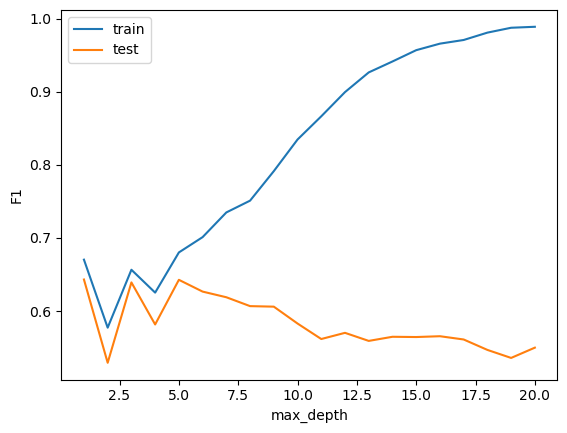

In [19]:
# У дерева при `max_depth` больше 8-10 F1 на обучающей выборке будет возрастающей функциией, 
# а на тестовой выборке убывающей из-за переобучения
depths = range(1, 21)
tr, te = [], []
for d in depths:
    p = Pipeline([("prep", prep),
                  ("model", DecisionTreeClassifier(max_depth=d, random_state=42))])
    p.fit(X_train, y_train)
    tr.append(f1_score(y_train, p.predict(X_train)))
    te.append(f1_score(y_test, p.predict(X_test)))

plt.plot(depths, tr, label="train")
plt.plot(depths, te, label="test")
plt.xlabel("max_depth"); plt.ylabel("F1"); plt.legend(); plt.show()

In [ ]:
# Гипотеза 5 подтвердилась по тренду, но не строго. В итоге дерево F1 запомнило обуч. выборку
# На тестовой выборке F1 колеблется в районе 0.5-0.6
# Модель переобучилась и стала выдавать результаты хуже и хуже

In [8]:
# Подбор гиперпараметров
pipe = Pipeline([("prep", prep), ("model", RidgeClassifier())])
grid_r = GridSearchCV(pipe, {"model__alpha": [0.01, 0.1, 1, 10, 100]}, cv=5, scoring="f1")
grid_r.fit(X_train, y_train)
print(grid_r.best_params_, round(grid_r.best_score_, 3))

pipe = Pipeline([("prep", prep), ("model", RandomForestClassifier(random_state=42))])
grid_f = GridSearchCV(pipe,
    {"model__n_estimators": [100, 200], "model__max_depth": [5, 10, None]},
    cv=5, scoring="f1", n_jobs=-1)
grid_f.fit(X_train, y_train)
print(grid_f.best_params_, round(grid_f.best_score_, 3))
print("F1 леса на тесте:", round(f1_score(y_test, grid_f.predict(X_test)), 3))

{'model__alpha': 10} 0.383
{'model__max_depth': None, 'model__n_estimators': 200} 0.628
F1 леса на тесте: 0.609


In [9]:
# отбор признаков
for k in [5, "all"]:
    p = Pipeline([("prep", prep), ("select", SelectKBest(f_classif, k=k)),
                  ("model", RidgeClassifier(alpha=1.0))])
    p.fit(X_train, y_train)
    print("k =", k, "| F1:", round(f1_score(y_test, p.predict(X_test)), 3))

k = 5 | F1: 0.346
k = all | F1: 0.342


In [20]:
# Гипотеза 6: Ridge с `class_weight="balanced"` поднимет F1 минимум на 0.1, потому что перестанет игнорировать редкий класс

from sklearn.metrics import recall_score
p = Pipeline([("prep", prep),
              ("model", RidgeClassifier(alpha=10, class_weight="balanced"))])
p.fit(X_train, y_train)
pred = p.predict(X_test)
print("F1:", round(f1_score(y_test, pred), 3),
      "| recall:", round(recall_score(y_test, pred), 3))

F1: 0.51 | recall: 0.733


In [16]:
# Гипотеза 6 подтвердилась, так как модели было задано, что пропустить покупателя хуже, чем
# назвать непокупателя покупателем. Модель находит покупателей чаще, но чаще определяет
# непокупателей в покупателей

In [21]:
# Гипотеза 7: `PageValues` окажется самым важным признаком у случайного леса, и без него F1 леса упадёт больше чем на 0.1

best = grid_f.best_estimator_
names = best.named_steps["prep"].get_feature_names_out()
imp = pd.Series(best.named_steps["model"].feature_importances_, index=names)
print(imp.sort_values(ascending=False).head(10))

# лес без PageValues
num2 = [c for c in num_cols if c != "PageValues"]
prep2 = ColumnTransformer([
    ("num", StandardScaler(), num2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
p2 = Pipeline([("prep", prep2),
               ("model", RandomForestClassifier(n_estimators=200, random_state=42))])
p2.fit(X_train.drop(columns="PageValues"), y_train)
pred2 = p2.predict(X_test.drop(columns="PageValues"))
print("F1 без PageValues:", round(f1_score(y_test, pred2), 3))

num__PageValues                 0.321957
num__ExitRates                  0.086385
num__ProductRelated_Duration    0.078694
num__ProductRelated             0.069498
num__Administrative_Duration    0.053530
num__BounceRates                0.051664
num__Administrative             0.044338
num__Informational_Duration     0.026263
num__Informational              0.018903
cat__Month_Nov                  0.018416
dtype: float64
F1 без PageValues: 0.167


In [ ]:
# PageValues оказалась опорным признаком для определения покупателей. Гипотеза подтвердилась